# Decision trees

This is an exploratory exercise to allow you to learn more about decision trees and how they might be used in scikit-learn.

## Instructions:

* Go through the notebook and complete the tasks. 
* Make sure you understand the examples given. If you need help, refer to the documentation links provided or go to the Topic 2 discussion forum. 
* When a question allows a free-form answer (e.g. what do you observe?), create a new markdown cell below and answer the question in the notebook. 
* Save your notebooks when you are done.

Before you do the tasks below, go through the scikit-learn decision tree tutorial <a href="https://scikit-learn.org/stable/modules/tree.html">here</a>, with the classifier described <a href="https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html">here</a>. The tutorial contains instructions on how to use decision trees for both classification and regression in Python. 

**Task 1:**
Using what you learnt in the scikit-learn decision tree tutorial, use decision trees for classification on the iris dataset, and for regression on the diabetes dataset (both included in ```sklearn.datasets```). Your code should print the accuracy and the confusion matrix for the classification problem, and mean squared error, root mean squared error, mean absolute error and the coefficient of determination $(R^2)$ (see Alpaydin, p. 80, for reference) for the regression. Try comparing the results for different maximum tree depths. 

Note: You should split your data 80% training and 20% for testing.



In [19]:
from sklearn import datasets
from sklearn import tree
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split

iris = datasets.load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

clf = tree.DecisionTreeClassifier(max_depth=2)
clf = clf.fit(X_train, y_train)

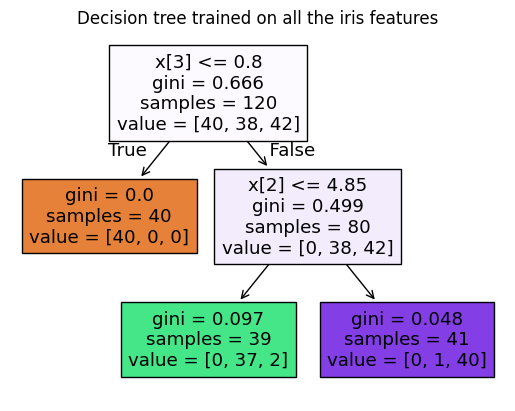

In [20]:
import matplotlib.pyplot as plt
plt.figure()
tree.plot_tree(clf, filled=True)
plt.title("Decision tree trained on all the iris features")
plt.show()

In [21]:
# accuracy and the confusion matrix for the classification problem
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score

y_pred = clf.predict(X_test)
print(confusion_matrix(y_test,y_pred))
print(accuracy_score(y_test,y_pred))

[[10  0  0]
 [ 0  9  3]
 [ 0  1  7]]
0.8666666666666667


Default free accuracy: 0.9333333333333333  
Max_depth 1: 0.6  
Max_dept 2: 0.8666666666666667

In [28]:
# Now evaluate a regression on the diabetes dataset 
from sklearn import tree

diabetes = datasets.load_diabetes()
X = diabetes.data
y = diabetes.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

regr = tree.DecisionTreeRegressor()
regr = regr.fit(X_train, y_train)

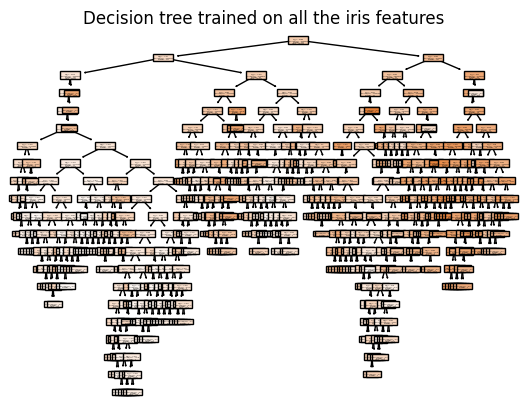

In [29]:
plt.figure()
tree.plot_tree(regr, filled=True)
plt.title("Decision tree trained on all the iris features")
plt.show()

In [31]:
y_pred = regr.predict(X_test)

Once you fitted your model, run it on the test set, and use these predictions to compute:
- the mean squared error $MSE = \frac{1}{n}\sum (y - \hat{y} )^2$, with $y$ being the ground truth values, $\hat{y}$ the model predictions, and $n$ the cardinality of $y$ (and $\hat{y}$),
- the root mean squared error $RMSE = \sqrt{ \frac{1}{n}\sum (y - \hat{y} )^2 }$
- the mean absolute error $MAE = \frac{1}{n} \sum (|y - \hat{y}|)$,
- and the coefficient of determination $(R^2)$, which is $1 - \frac{SS_{res} }{ SS_{tot}}$, where $SS_{res}$ is the sum of squares of residuals $\sum (y - \hat{y})^2$, and $SS_{tot}$ is the total sum of squares $\sum (y - \mu_y)^2$ ($\mu_y$ being the mean of the ground truth values. Note that this metric is available under the `.score` method of your model object.

In [34]:
# accuracy and the confusion matrix for the classification problem
import numpy as np
from sklearn.metrics import confusion_matrix
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Metrics
MSE = mean_squared_error(y_test, y_pred)
RMSE = np.sqrt(MSE)
MAE = mean_absolute_error(y_test, y_pred)
R2 = regr.score(X_test, y_test)

# Output
print(f"MSE: {MSE:.2f}")
print(f"RMSE: {RMSE:.2f}")
print(f"MAE: {MAE:.2f}")
print(f"R²: {R2:.2f}")


MSE: 6150.81
RMSE: 78.43
MAE: 59.21
R²: -0.21


**Task 2:**
How would you avoid overfitting in decision trees? Read the decision tree classifier described <a href="http://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html">here</a> for help. 




- Cutting the depth of the tree
- Defining a min. number of features that can be leaf
- Using random splitting
- Change the minimum number of samples required to split from 2
- Consider a max. number of features